In [1]:
# ==========================================
# AGRIDETECT-AI
# MEMBER 1: DATASET EXPLORATION
# ==========================================

import os
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
input_path = Path("/kaggle/input")

print("Available datasets:\n")

for item in input_path.iterdir():
    print(item)

Available datasets:

/kaggle/input/datasets


In [3]:
# Explore the dataset directory structure

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    level = root.replace("/kaggle/input/datasets", "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

datasets/
  vipoooool/
    new-plant-diseases-dataset/
      New Plant Diseases Dataset(Augmented)/
      new plant diseases dataset(augmented)/
      test/


In [5]:
# Set the main dataset location

dataset_dir = Path(
    "/kaggle/input/datasets/vipoonool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)"
)

# Display only the immediate folders

print("Folders inside dataset:\n")

for item in dataset_dir.iterdir():
    if item.is_dir():
        print("📁", item.name)

Folders inside dataset:



FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/vipoonool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)'

In [6]:
import os

print("Contents of /kaggle/input:\n")

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 4:
        print("  " * level + os.path.basename(root) + "/")

Contents of /kaggle/input:

input/
  datasets/
    vipoooool/
      new-plant-diseases-dataset/
        New Plant Diseases Dataset(Augmented)/
        new plant diseases dataset(augmented)/
        test/


In [8]:
import os

print("EXACT DATASET FOLDER STRUCTURE\n")

for root, dirs, files in os.walk("/kaggle/input"):

    depth = root.replace("/kaggle/input", "").count(os.sep)

    if depth <= 5:
        print("Folder:", root)

    # Don't scan deeper than necessary
    if depth >= 5:
        dirs.clear()

EXACT DATASET FOLDER STRUCTURE

Folder: /kaggle/input
Folder: /kaggle/input/datasets
Folder: /kaggle/input/datasets/vipoooool
Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset
Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)
Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)
Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)
Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)
Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test
Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test


In [9]:
# Find actual training, validation and test folders

import os

search_path = "/kaggle/input"

found_folders = []

for root, dirs, files in os.walk(search_path):

    folder_name = os.path.basename(root).lower()

    if folder_name in ["train", "valid", "validation", "test"]:
        found_folders.append(root)

print("DATASET FOLDERS FOUND:\n")

for folder in found_folders:
    print(folder)

DATASET FOLDERS FOUND:

/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test


In [10]:
# Compare the two available training and validation folders

from pathlib import Path

base = Path("/kaggle/input/datasets")

train_folders = list(base.rglob("train"))

for i, train in enumerate(train_folders, start=1):

    valid = train.parent / "valid"

    if not valid.exists():
        continue

    train_classes = sorted([
        p.name for p in train.iterdir() if p.is_dir()
    ])

    valid_classes = sorted([
        p.name for p in valid.iterdir() if p.is_dir()
    ])

    print("\n", "=" * 50)
    print("DATASET COPY", i)
    print("=" * 50)

    print("Training path:", train)
    print("Validation path:", valid)

    print("Training classes:", len(train_classes))
    print("Validation classes:", len(valid_classes))

    print("Same classes in both splits:",
          set(train_classes) == set(valid_classes))

    print("First 5 classes:", train_classes[:5])


DATASET COPY 1
Training path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
Validation path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid
Training classes: 38
Validation classes: 38
Same classes in both splits: True
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']

DATASET COPY 2
Training path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Validation path: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
Training classes: 38
Validation classes: 38
Same classes in both splits: True
First 5 classes: ['Apple___Apple_scab', 'Apple___

In [11]:
# Compare image counts in both dataset copies

from pathlib import Path
import pandas as pd

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find both training folders
train_folders = [
    p for p in Path("/kaggle/input").rglob("train")
    if p.is_dir() and (p.parent / "valid").is_dir()
]

comparison = []

for i, train in enumerate(train_folders, start=1):

    valid = train.parent / "valid"

    classes = sorted([
        p.name for p in train.iterdir() if p.is_dir()
    ])

    train_total = 0
    valid_total = 0

    for class_name in classes:

        train_class = train / class_name
        valid_class = valid / class_name

        train_count = sum(
            1 for f in train_class.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        )

        valid_count = sum(
            1 for f in valid_class.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        )

        train_total += train_count
        valid_total += valid_count

    comparison.append({
        "Copy": i,
        "Training Classes": len(classes),
        "Training Images": train_total,
        "Validation Images": valid_total,
        "Total Images": train_total + valid_total,
        "Training Path": str(train)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

KeyboardInterrupt: 

In [12]:
# FAST COMPARISON OF BOTH DATASET COPIES

from pathlib import Path

base = Path("/kaggle/input")

train_folders = [
    p for p in base.rglob("train")
    if p.is_dir() and (p.parent / "valid").is_dir()
]

for i, train in enumerate(train_folders, start=1):

    valid = train.parent / "valid"

    train_classes = [
        p for p in train.iterdir() if p.is_dir()
    ]

    valid_classes = [
        p for p in valid.iterdir() if p.is_dir()
    ]

    print(f"\nDATASET COPY {i}")
    print("Training classes:", len(train_classes))
    print("Validation classes:", len(valid_classes))

    print("Training folders:", len(list(train.iterdir())))
    print("Validation folders:", len(list(valid.iterdir())))


DATASET COPY 1
Training classes: 38
Validation classes: 38
Training folders: 38
Validation folders: 38

DATASET COPY 2
Training classes: 38
Validation classes: 38
Training folders: 38
Validation folders: 38


In [13]:
# Select Dataset Copy 1

train_dir = train_folders[0]
valid_dir = train_dir.parent / "valid"

print("Selected training directory:")
print(train_dir)

print("\nSelected validation directory:")
print(valid_dir)

print("\nDataset paths verified:",
      train_dir.exists() and valid_dir.exists())

Selected training directory:
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train

Selected validation directory:
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid

Dataset paths verified: True


In [14]:
# Identify all plant disease classes

classes = sorted([
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir()
])

print("TOTAL NUMBER OF CLASSES:", len(classes))

print("\nLIST OF ALL CLASSES:\n")

for i, name in enumerate(classes, start=1):
    print(f"{i}. {name}")

TOTAL NUMBER OF CLASSES: 38

LIST OF ALL CLASSES:

1. Apple___Apple_scab
2. Apple___Black_rot
3. Apple___Cedar_apple_rust
4. Apple___healthy
5. Blueberry___healthy
6. Cherry_(including_sour)___Powdery_mildew
7. Cherry_(including_sour)___healthy
8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
9. Corn_(maize)___Common_rust_
10. Corn_(maize)___Northern_Leaf_Blight
11. Corn_(maize)___healthy
12. Grape___Black_rot
13. Grape___Esca_(Black_Measles)
14. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15. Grape___healthy
16. Orange___Haunglongbing_(Citrus_greening)
17. Peach___Bacterial_spot
18. Peach___healthy
19. Pepper,_bell___Bacterial_spot
20. Pepper,_bell___healthy
21. Potato___Early_blight
22. Potato___Late_blight
23. Potato___healthy
24. Raspberry___healthy
25. Soybean___healthy
26. Squash___Powdery_mildew
27. Strawberry___Leaf_scorch
28. Strawberry___healthy
29. Tomato___Bacterial_spot
30. Tomato___Early_blight
31. Tomato___Late_blight
32. Tomato___Leaf_Mold
33. Tomato___Septoria_leaf

In [15]:
# ==========================================
# COUNT IMAGES IN ALL 38 CLASSES
# ==========================================

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

train_counts = {}
valid_counts = {}

for class_name in classes:

    # Training image count
    train_folder = train_dir / class_name

    train_count = sum(
        1 for file in train_folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in image_extensions
    )

    # Validation image count
    valid_folder = valid_dir / class_name

    valid_count = sum(
        1 for file in valid_folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in image_extensions
    )

    train_counts[class_name] = train_count
    valid_counts[class_name] = valid_count

print("Image counting completed!")

KeyboardInterrupt: 

In [16]:
# FAST IMAGE COUNTING USING os.scandir()

import os
from collections import Counter

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

train_counts = {}
valid_counts = {}

def fast_count_images(folder):

    count = 0

    with os.scandir(folder) as entries:

        for entry in entries:

            if entry.is_file():
                extension = os.path.splitext(entry.name)[1].lower()

                if extension in image_extensions:
                    count += 1

    return count


print("Starting image counting...\n")

for i, class_name in enumerate(classes, start=1):

    train_counts[class_name] = fast_count_images(
        train_dir / class_name
    )

    valid_counts[class_name] = fast_count_images(
        valid_dir / class_name
    )

    print(f"{i}/38 completed: {class_name}")

print("\nIMAGE COUNTING COMPLETED!")

Starting image counting...

1/38 completed: Apple___Apple_scab
2/38 completed: Apple___Black_rot
3/38 completed: Apple___Cedar_apple_rust
4/38 completed: Apple___healthy
5/38 completed: Blueberry___healthy
6/38 completed: Cherry_(including_sour)___Powdery_mildew
7/38 completed: Cherry_(including_sour)___healthy
8/38 completed: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
9/38 completed: Corn_(maize)___Common_rust_
10/38 completed: Corn_(maize)___Northern_Leaf_Blight
11/38 completed: Corn_(maize)___healthy
12/38 completed: Grape___Black_rot
13/38 completed: Grape___Esca_(Black_Measles)
14/38 completed: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15/38 completed: Grape___healthy
16/38 completed: Orange___Haunglongbing_(Citrus_greening)
17/38 completed: Peach___Bacterial_spot
18/38 completed: Peach___healthy
19/38 completed: Pepper,_bell___Bacterial_spot
20/38 completed: Pepper,_bell___healthy
21/38 completed: Potato___Early_blight
22/38 completed: Potato___Late_blight
23/38 complete

In [17]:
# Create dataset statistics table

df = pd.DataFrame({
    "Class": classes,
    "Training Images": [train_counts[c] for c in classes],
    "Validation Images": [valid_counts[c] for c in classes]
})

df["Total Images"] = (
    df["Training Images"] + df["Validation Images"]
)

display(df)

,Class,Training Images,Validation Images,Total Images
0,Apple___Apple_scab,2016,504,2520
1,Apple___Black_rot,1987,497,2484
2,Apple___Cedar_apple_rust,1760,440,2200
3,Apple___healthy,2008,502,2510
4,Blueberry___healthy,1816,454,2270
5,Cherry_(including_sour)___Powdery_mildew,1683,421,2104
6,Cherry_(including_sour)___healthy,1826,456,2282
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,1642,410,2052
8,Corn_(maize)___Common_rust_,1907,477,2384
9,Corn_(maize)___Northern_Leaf_Blight,1908,477,2385


In [19]:
# Overall dataset statistics

total_train = df["Training Images"].sum()
total_valid = df["Validation Images"].sum()
total_images = df["Total Images"].sum()

print("DATASET STATISTICS")
print("-" * 40)

print("Number of classes:", len(classes))
print("Training images:", total_train)
print("Validation images:", total_valid)
print("Total images:", total_images)

print("Average images per class:",
      round(df["Total Images"].mean(), 2))

DATASET STATISTICS
----------------------------------------
Number of classes: 38
Training images: 70295
Validation images: 17572
Total images: 87867
Average images per class: 2312.29


In [20]:
max_class = df.loc[df["Training Images"].idxmax()]
min_class = df.loc[df["Training Images"].idxmin()]

print("Maximum images:")
print(max_class["Class"], "-", max_class["Training Images"])

print("\nMinimum images:")
print(min_class["Class"], "-", min_class["Training Images"])

ratio = (
    max_class["Training Images"] /
    min_class["Training Images"]
)

print("\nMaximum/Minimum ratio:", round(ratio, 2))

Maximum images:
Soybean___healthy - 2022

Minimum images:
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot - 1642

Maximum/Minimum ratio: 1.23


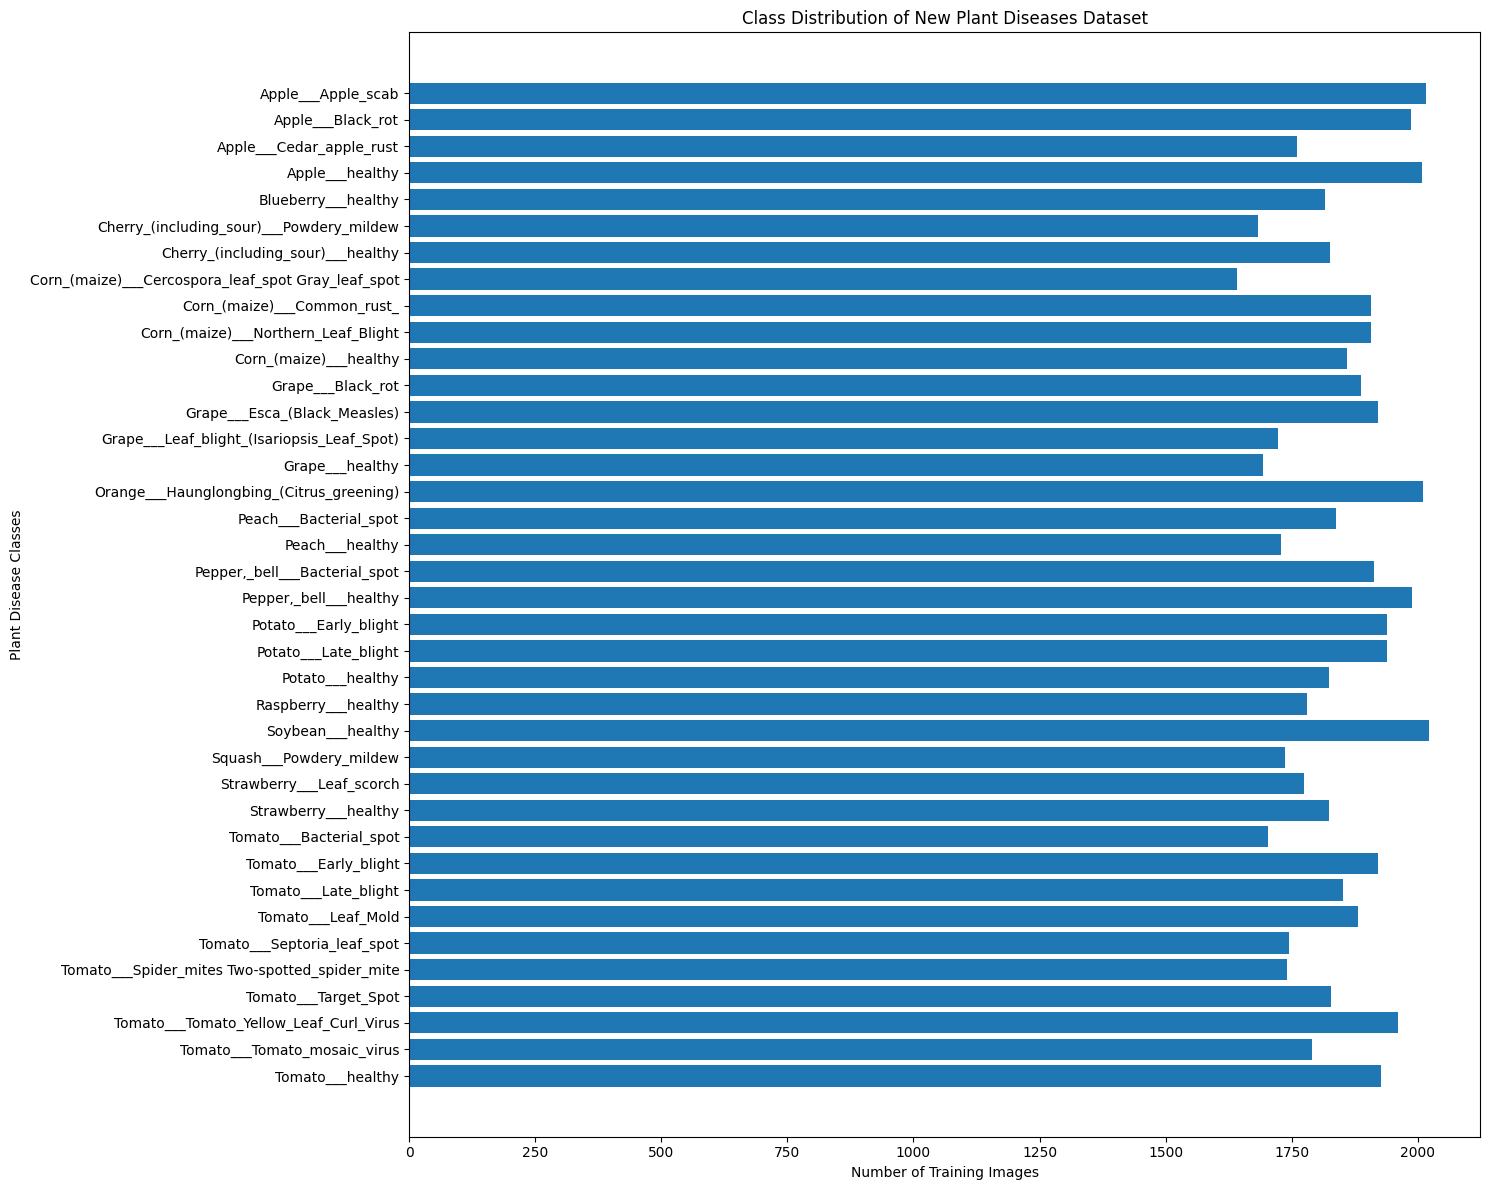

In [21]:
# Class Distribution Chart

plt.figure(figsize=(15, 12))

plt.barh(
    df["Class"],
    df["Training Images"]
)

plt.xlabel("Number of Training Images")
plt.ylabel("Plant Disease Classes")

plt.title(
    "Class Distribution of New Plant Diseases Dataset"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "/kaggle/working/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

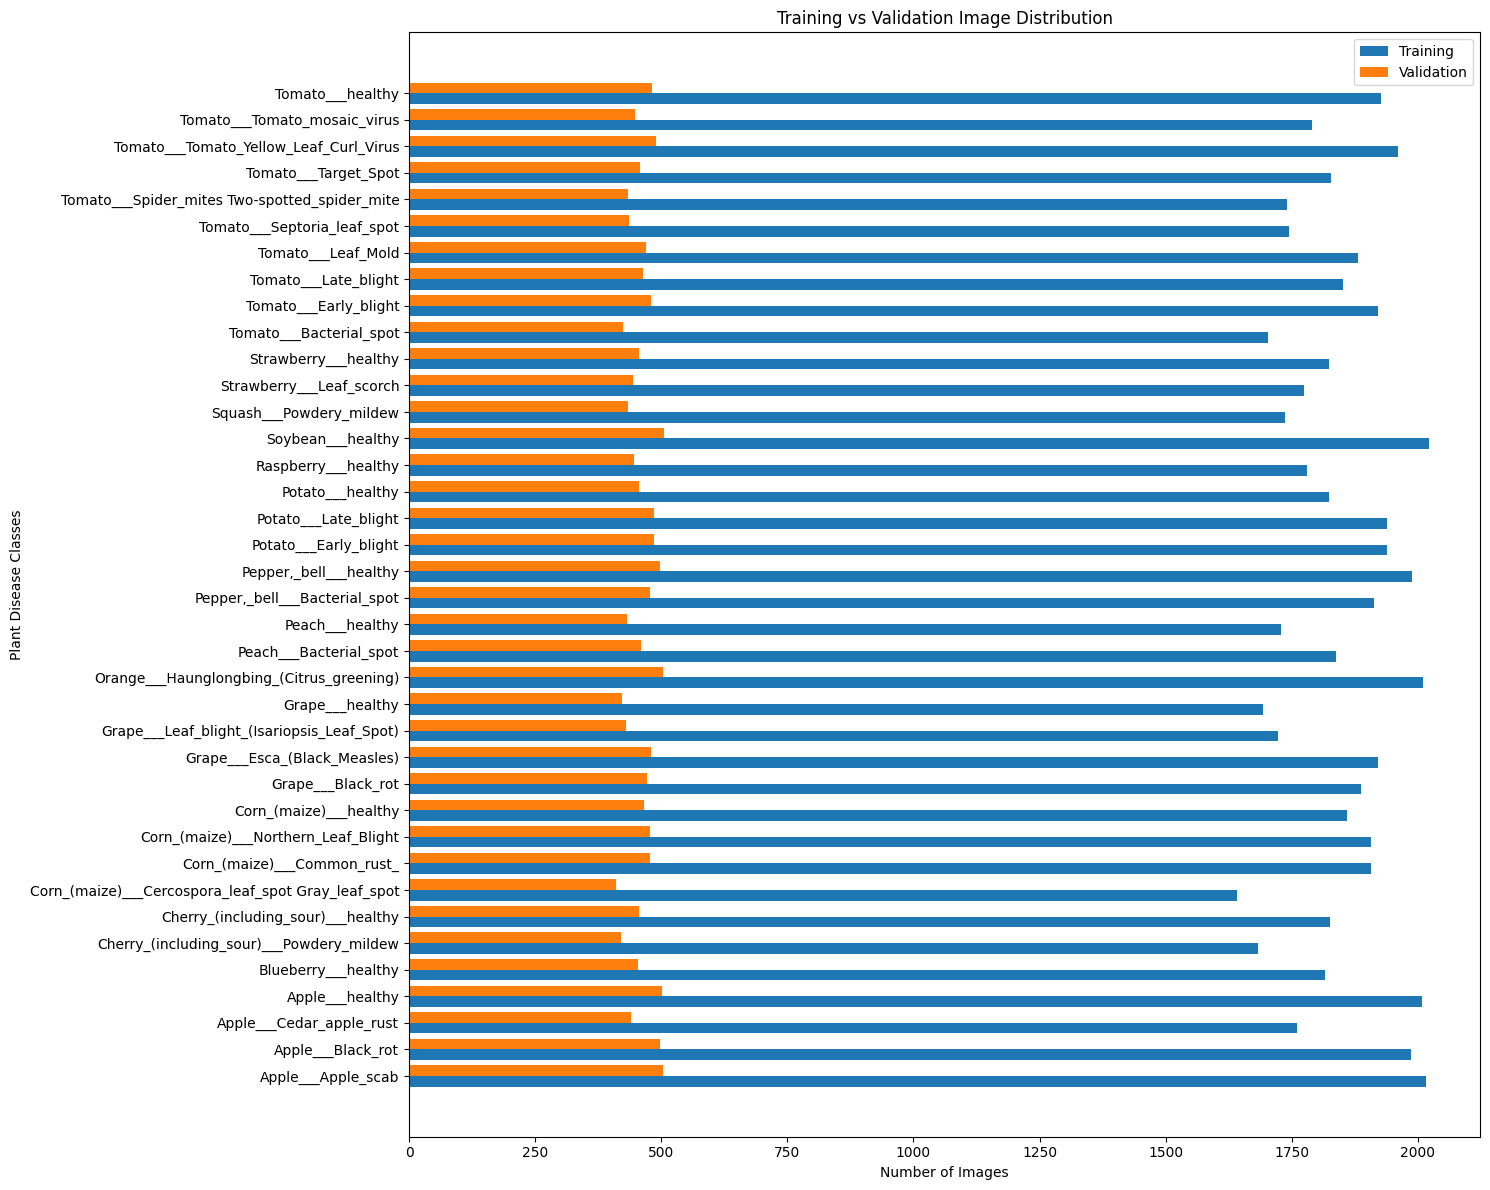

In [22]:
plt.figure(figsize=(15, 12))

y = np.arange(len(classes))

plt.barh(
    y - 0.2,
    df["Training Images"],
    height=0.4,
    label="Training"
)

plt.barh(
    y + 0.2,
    df["Validation Images"],
    height=0.4,
    label="Validation"
)

plt.yticks(y, classes)
plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Classes")
plt.title("Training vs Validation Image Distribution")

plt.legend()
plt.tight_layout()

plt.savefig(
    "/kaggle/working/train_validation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

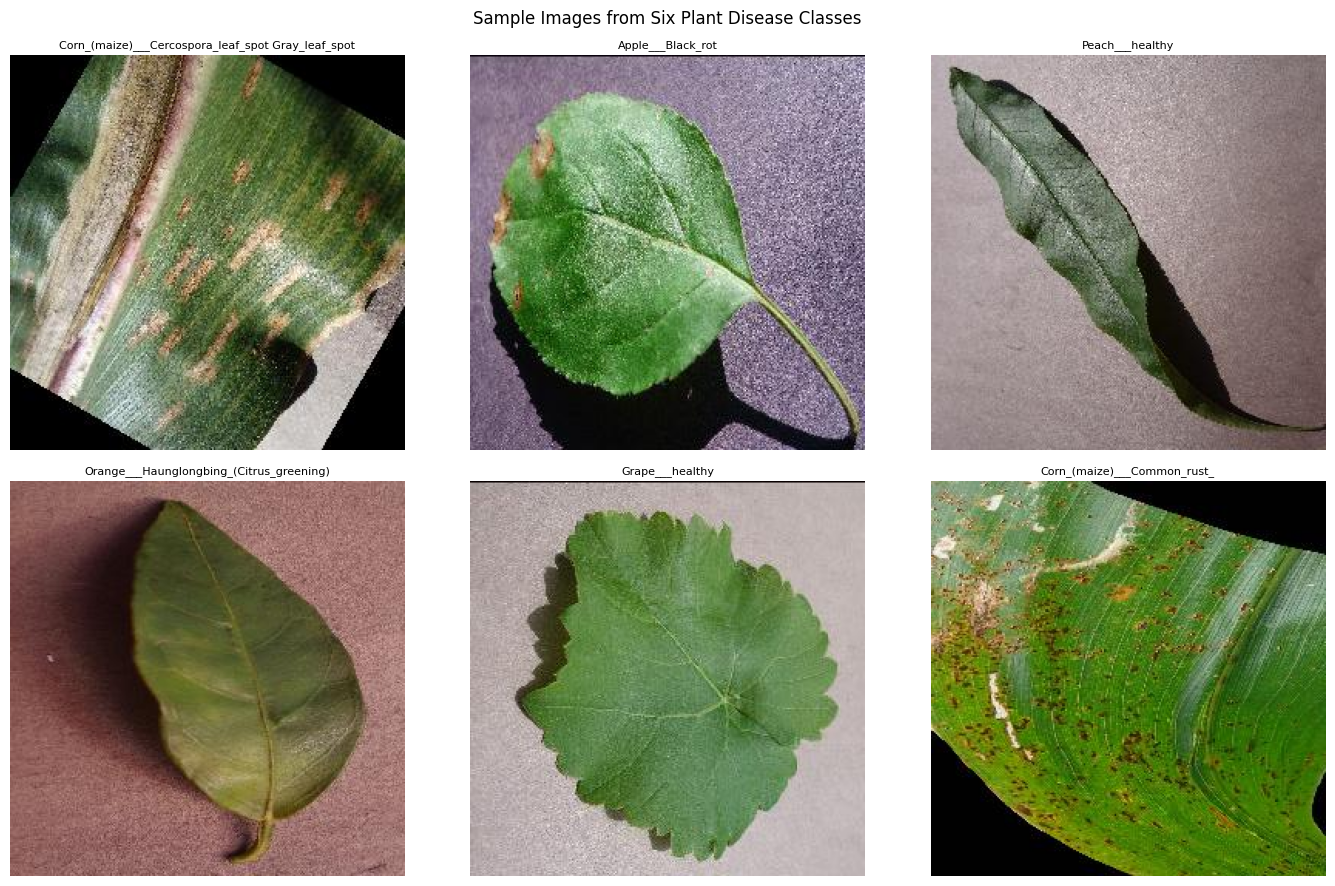

In [23]:
random.seed(42)

selected_classes = random.sample(classes, 6)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, class_name in zip(axes.flat, selected_classes):

    folder = train_dir / class_name

    image_files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name, fontsize=8)
    ax.axis("off")

plt.suptitle("Sample Images from Six Plant Disease Classes")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
summary = pd.DataFrame({
    "Metric": [
        "Number of Classes",
        "Training Images",
        "Validation Images",
        "Total Images",
        "Average Images per Class",
        "Maximum Training Images",
        "Minimum Training Images",
        "Training Percentage",
        "Validation Percentage"
    ],

    "Value": [
        len(classes),
        total_train,
        total_valid,
        total_images,
        round(total_images / len(classes), 2),
        df.loc[df["Training Images"].idxmax(), "Class"],
        df.loc[df["Training Images"].idxmin(), "Class"],
        round((total_train / total_images) * 100, 2),
        round((total_valid / total_images) * 100, 2)
    ]
})

display(summary)

,Metric,Value
0,Number of Classes,38
1,Training Images,70295
2,Validation Images,17572
3,Total Images,87867
4,Average Images per Class,2312.29
5,Maximum Training Images,Soybean___healthy
6,Minimum Training Images,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...
7,Training Percentage,80.0
8,Validation Percentage,20.0


In [25]:
df.to_csv(
    "/kaggle/working/class_distribution.csv",
    index=False
)

summary.to_csv(
    "/kaggle/working/dataset_statistics.csv",
    index=False
)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!


## Dataset Exploration – Observations and Findings

### 1. Dataset Overview
The New Plant Diseases Dataset (Augmented) was selected for the plant disease detection project. It contains 38 different plant disease and healthy-leaf categories.

### 2. Dataset Statistics
- Total images: 87,867
- Training images: 70,295
- Validation images: 17,572
- Number of classes: 38
- Average images per class: 2,312.29
- Dataset split: 80% training and 20% validation.

### 3. Class Distribution
The number of training images ranges from approximately 1,642 to 2,022 per class. The maximum-to-minimum ratio is approximately 1.23, indicating a relatively balanced class distribution.

### 4. Visual Inspection
Sample images from six randomly selected classes were visualized. The images contain different plant species, healthy leaves, and visible disease symptoms.

### 5. Key Findings
- The dataset covers 38 plant disease and healthy categories.
- Both training and validation datasets contain images from all 38 classes.
- The class distribution does not show severe imbalance based on image counts.
- Visual differences in leaf appearance and disease symptoms can be observed across categories.

### 6. Conclusion
The initial exploration indicates that the dataset is suitable for proceeding to the next stages of the plant disease detection pipeline. Further image quality checks, duplicate detection, preprocessing, and validation will be required before model training.